# Trying to figure out why the $\pm$ 6 ray paths diverge

In [1]:
import os
import pickle

import cmocean
import matplotlib.pyplot as plt
import numpy as np
import pygenray as pr
import xarray as xr
from dotenv import find_dotenv, load_dotenv

_ = load_dotenv(find_dotenv())

%config InlineBackend.figure_format = 'retina'

In [ ]:
fn = f"{os.environ['NESCAFE23_DATADIR']}environment_data/dataproducts/full_field.nc"
full_field = xr.open_dataset(fn)

fn = f"{os.environ['NESCAFE23_DATADIR']}dataproducts/ray_run_forward_back.pkl"

with open(fn, "rb") as f:
    ray_run = pickle.load(f)

eigs = ray_run["eigs"]
eigs_back = ray_run["eigs_back"]
envi = ray_run["envi"]
envi_back = ray_run["envi_back"]

In [3]:
%matplotlib inline

In [4]:
plt.close("all")

Text(0, 0.5, 'depth [m]')

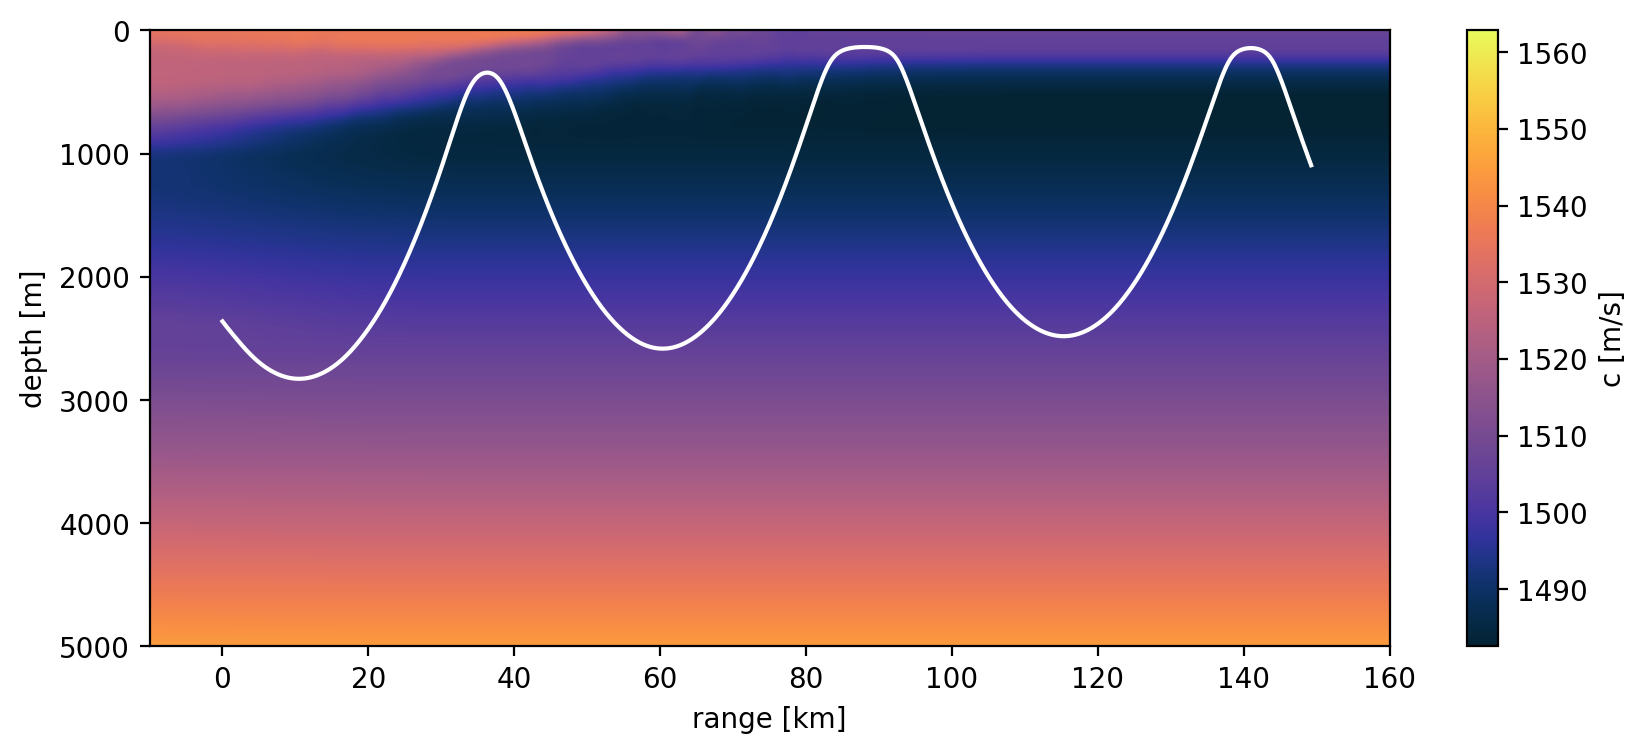

In [58]:
fig = plt.figure(figsize=(10, 4))

eig_idx = np.where(eigs.ray_id[0] == "-6.0")[0][0]

full_field["c"].assign_coords({"range": full_field.range / 1000 + 35}).plot(
    cmap=cmocean.cm.thermal
)

plt.plot(eigs.rs[0][eig_idx, :] / 1000, -eigs.zs[0][eig_idx, :], c="w")
plt.ylim([5000, 0])
plt.xlim([-10, 160])
plt.xlabel("range [km]")
plt.ylabel("depth [m]")

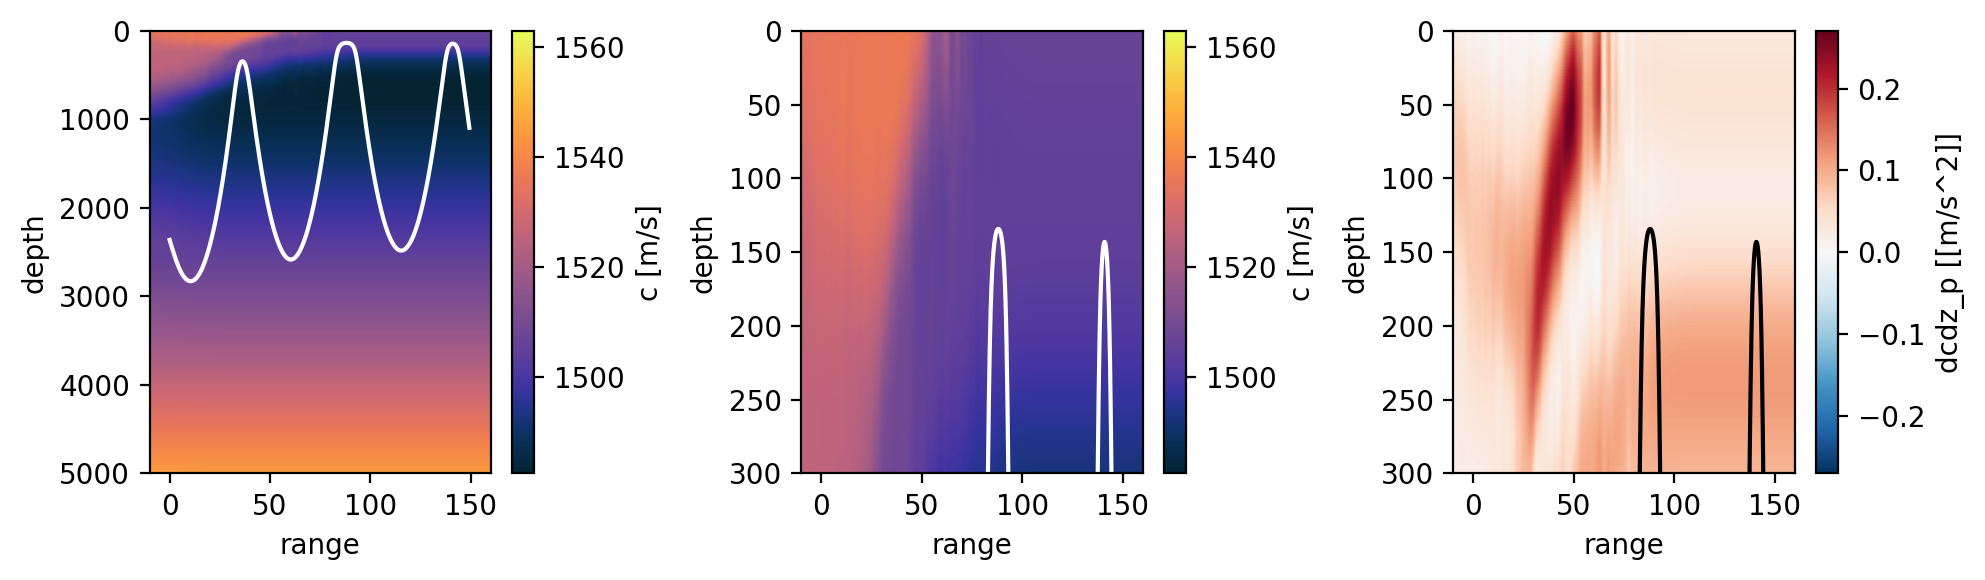

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes = axes.flatten()

plt.sca(axes[0])
eig_idx = np.where(eigs.ray_id[0] == "-6.0")[0][0]

full_field["c"].assign_coords({"range": full_field.range / 1000 + 35}).plot(
    cmap=cmocean.cm.thermal
)

plt.plot(eigs.rs[0][eig_idx, :] / 1000, -eigs.zs[0][eig_idx, :], c="w")
plt.ylim([5000, 0])
plt.xlim([-10, 160])

# plt.grid()
# plt.xlim([75,110])

plt.sca(axes[2])
eig_idx = np.where(eigs.ray_id[0] == "-6.0")[0][0]

full_field["dcdz_p"].assign_coords({"range": full_field.range / 1000 + 35}).plot()

plt.plot(eigs.rs[0][eig_idx, :] / 1000, -eigs.zs[0][eig_idx, :], c="k")
plt.ylim([5000, 0])
plt.xlim([-10, 160])

# plt.grid()
# plt.xlim([75,110])
plt.ylim([300, 0])


plt.sca(axes[1])
full_field["c"].assign_coords({"range": full_field.range / 1000 + 35}).plot(
    cmap=cmocean.cm.thermal
)
plt.plot(eigs.rs[0][eig_idx, :] / 1000, -eigs.zs[0][eig_idx, :], c="w")

plt.xlim([-10, 160])
plt.ylim([300, 0])


plt.tight_layout()

plt.show()

In [42]:
np.max(eigs.zs[0][eig_idx, :])

np.float64(-134.1972354293659)

(0.0, 200.0)

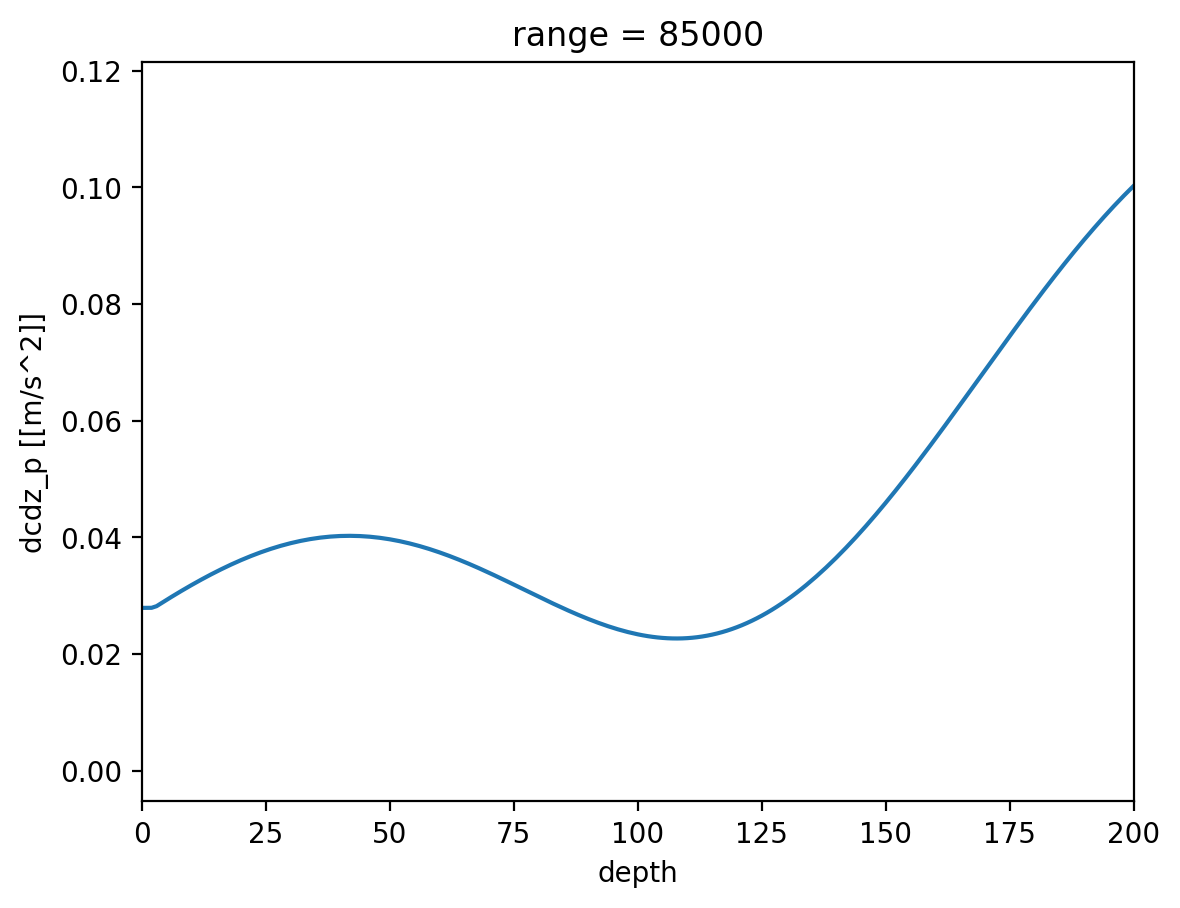

In [45]:
full_field["dcdz_p"].sel({"range": 85000}).plot()
plt.xlim([0, 200])

## plot profiles

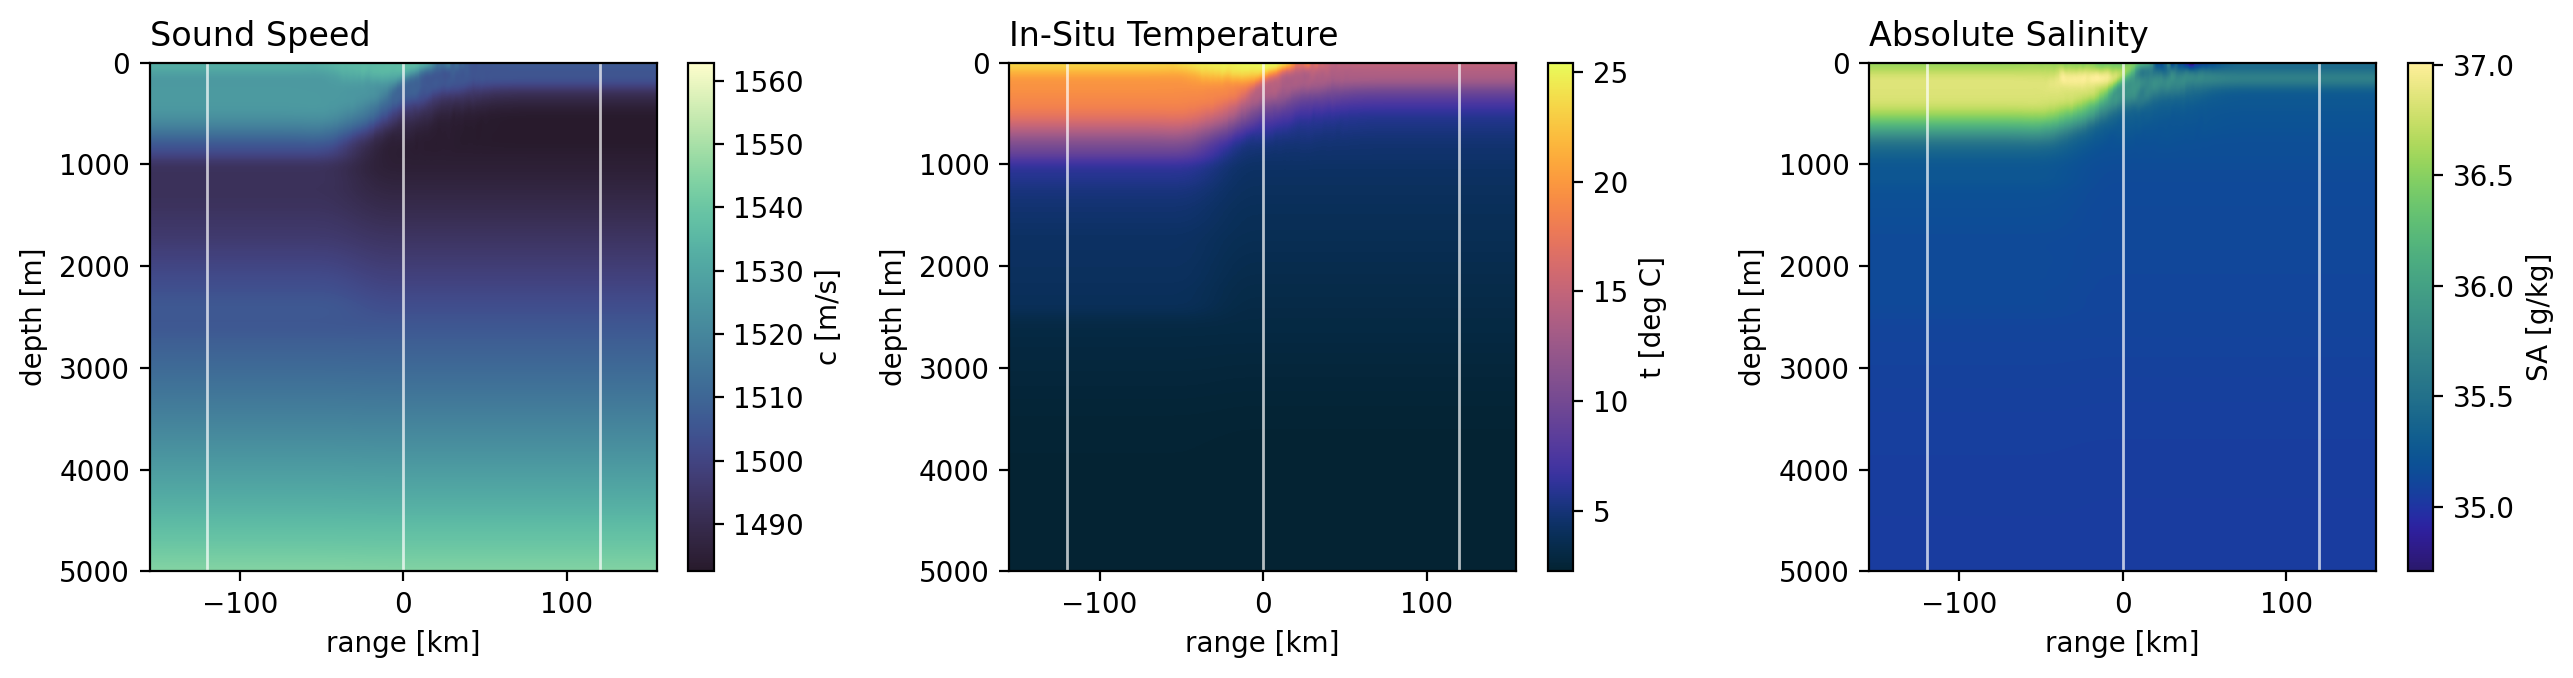

In [83]:
fig = plt.figure(figsize=(13, 3.5))

ylims = [5000, 0]

plt.subplot(1, 3, 1)
full_field["c"].assign_coords({"range": full_field.range / 1000}).plot(
    x="range", cmap=cmocean.cm.deep_r
)
plt.vlines([-120, 0, 120], ylims[0], ylims[1], lw=1, colors="white", alpha=0.7)

plt.ylim([5000, 0])
plt.xlabel("range [km]")
plt.ylabel("depth [m]")
plt.title("Sound Speed", loc="left")

plt.subplot(1, 3, 2)
full_field["t"].assign_coords({"range": full_field.range / 1000}).plot(
    x="range", cmap=cmocean.cm.thermal
)
plt.vlines([-120, 0, 120], ylims[0], ylims[1], lw=1, colors="white", alpha=0.7)

plt.ylim([5000, 0])
plt.xlabel("range [km]")
plt.ylabel("depth [m]")
plt.title("In-Situ Temperature", loc="left")

plt.subplot(1, 3, 3)
full_field["SA"].assign_coords({"range": full_field.range / 1000}).plot(
    x="range", cmap=cmocean.cm.haline
)
plt.vlines([-120, 0, 120], ylims[0], ylims[1], lw=1, colors="white", alpha=0.7)

plt.ylim([5000, 0])
plt.xlabel("range [km]")
plt.ylabel("depth [m]")
plt.title("Absolute Salinity", loc="left")

plt.tight_layout()

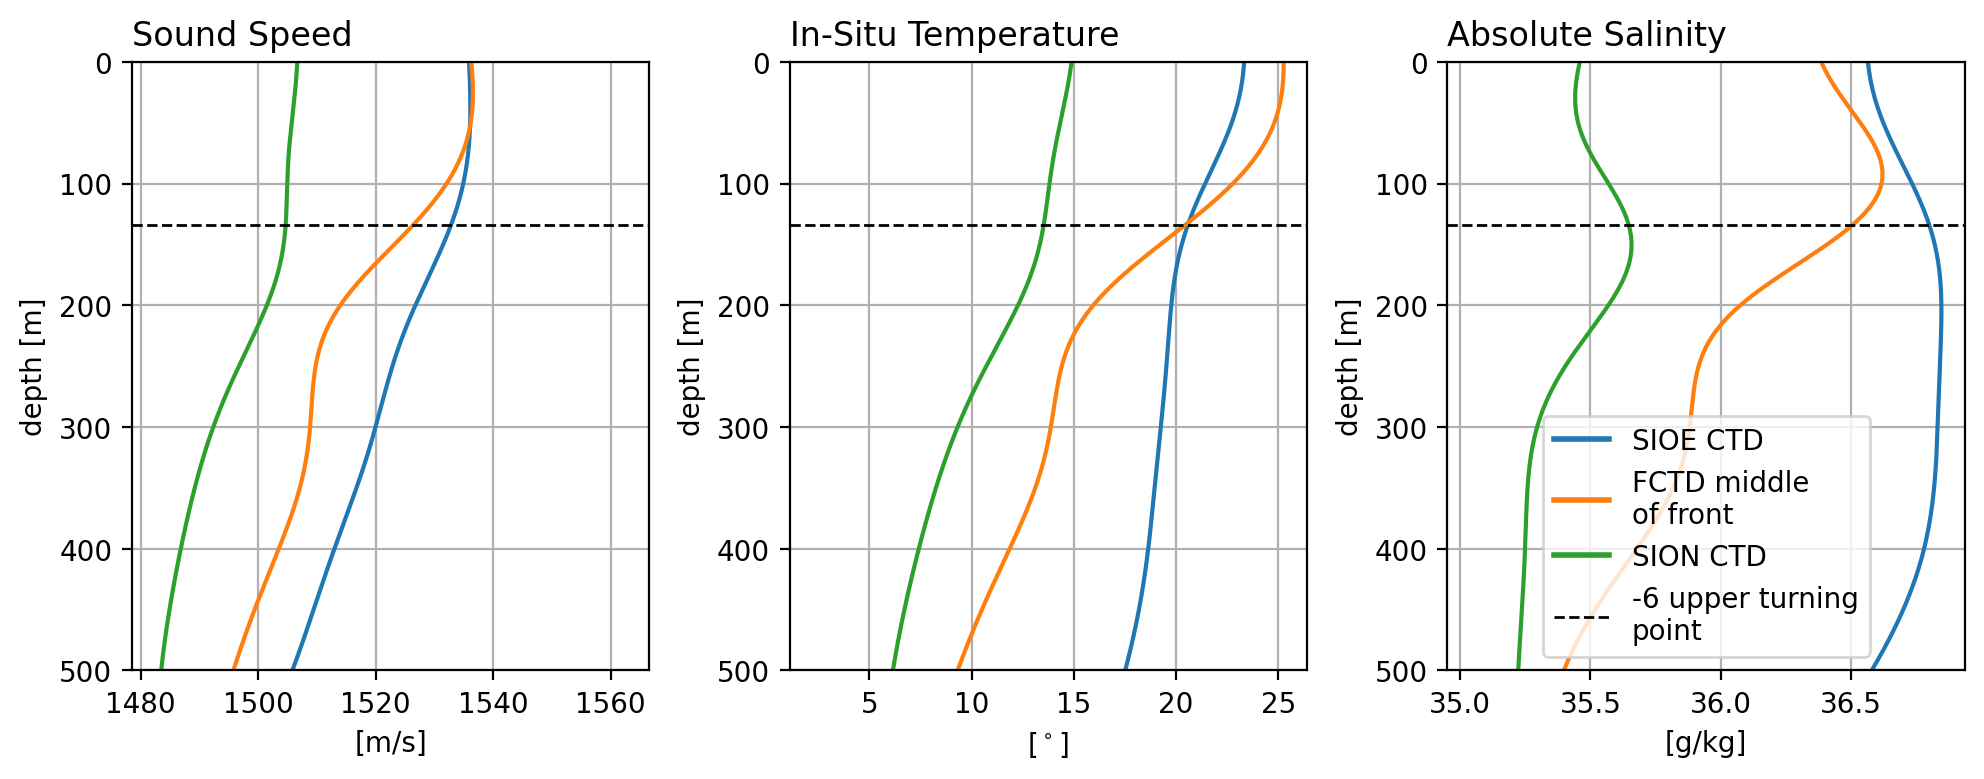

In [87]:
fig = plt.figure(figsize=(10, 4))

ylims = [500, 0]

plt.subplot(1, 3, 1)
plt.plot(full_field["c"].sel({"range": -12000}, method="nearest"), full_field.depth)
plt.plot(full_field["c"].sel({"range": 0}, method="nearest"), full_field.depth)
plt.plot(full_field["c"].sel({"range": 120000}, method="nearest"), full_field.depth)
plt.title("Sound Speed", loc="left")
plt.ylim(ylims)
plt.ylabel("depth [m]")
plt.xlabel("[m/s]")

xlims = plt.gca().get_xlim()
plt.hlines(
    -np.max(eigs.zs[0][eig_idx, :]),
    xlims[0],
    xlims[1],
    lw=1,
    linestyle="--",
    colors="k",
)
plt.xlim(xlims)
plt.grid()

plt.subplot(1, 3, 2)
plt.plot(full_field["t"].sel({"range": -120000}, method="nearest"), full_field.depth)
plt.plot(full_field["t"].sel({"range": 0}, method="nearest"), full_field.depth)
plt.plot(full_field["t"].sel({"range": 120000}, method="nearest"), full_field.depth)
plt.title("In-Situ Temperature", loc="left")
plt.ylim(ylims)
plt.ylabel("depth [m]")
plt.xlabel("[$^\\circ$]")

xlims = plt.gca().get_xlim()
plt.hlines(
    -np.max(eigs.zs[0][eig_idx, :]),
    xlims[0],
    xlims[1],
    lw=1,
    linestyle="--",
    colors="k",
)
plt.xlim(xlims)
plt.grid()
plt.subplot(1, 3, 3)
plt.plot(
    full_field["SA"].sel({"range": -120000}, method="nearest"),
    full_field.depth,
    label="SIOE CTD",
)
plt.plot(
    full_field["SA"].sel({"range": 0}, method="nearest"),
    full_field.depth,
    label="FCTD middle\nof front",
)
plt.plot(
    full_field["SA"].sel({"range": 120000}, method="nearest"),
    full_field.depth,
    label="SION CTD",
)
plt.title("Absolute Salinity", loc="left")
plt.ylim(ylims)
plt.ylabel("depth [m]")
plt.xlabel("[g/kg]")

xlims = plt.gca().get_xlim()
plt.hlines(
    -np.max(eigs.zs[0][eig_idx, :]),
    xlims[0],
    xlims[1],
    lw=1,
    linestyle="--",
    colors="k",
    label="-6 upper turning\npoint",
)
plt.xlim(xlims)
plt.grid()

# Make legend lines thicker
leg = plt.legend()
for k, line in enumerate(leg.get_lines()):
    if k > 2:
        break
    line.set_linewidth(2)

plt.tight_layout(pad=1)

### Try running some rays

In [51]:
bathy = xr.DataArray(
    np.linspace(4908, 4908, 100),
    dims=["range"],
    coords={"range": np.linspace(0, 200e3, 100)},
)

front_location = 35e3

c = full_field["c"].assign_coords({"range": full_field.range + front_location})

envi = pr.OceanEnvironment2D(c, bathy)

In [52]:
source_depth = 2300
thetas = np.linspace(-35, 35, 5000)
reciever_range = 150e3

rays = pr.shoot_rays(source_depth, 0, thetas, reciever_range, 1000, envi)

Computing ray fan: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:32<00:00, 155.65it/s]


In [56]:
receiver_depths = [1000]
eigs = pr.find_eigenrays(
    rays, receiver_depths, source_depth, 0, reciever_range, 1000, envi
)

Finding eigenrays: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 38/38 [00:05<00:00,  7.39it/s]


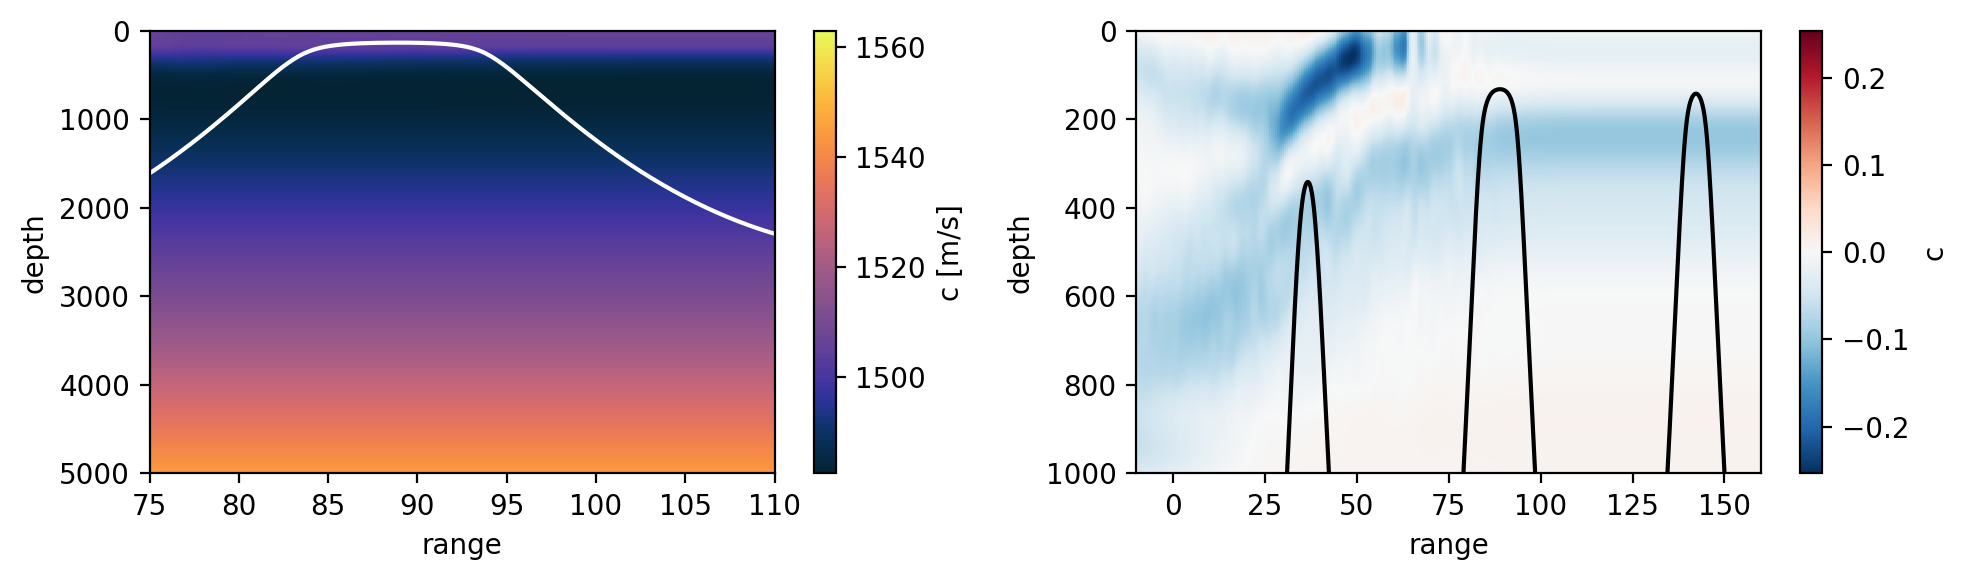

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes = axes.flatten()

plt.sca(axes[0])
eig_idx = np.where(eigs.ray_id[0] == "-6.0")[0][0]

full_field["c"].assign_coords({"range": full_field.range / 1000 + 35}).plot(
    cmap=cmocean.cm.thermal
)

plt.plot(eigs.rs[0][eig_idx, :] / 1000, -eigs.zs[0][eig_idx, :], c="w")
plt.ylim([5000, 0])
plt.xlim([-10, 160])

plt.xlim([75, 110])

plt.sca(axes[1])
eig_idx = np.where(eigs.ray_id[0] == "-6.0")[0][0]

full_field["c"].differentiate("depth").assign_coords({
    "range": full_field.range / 1000 + 35
}).plot()

plt.plot(eigs.rs[0][eig_idx, :] / 1000, -eigs.zs[0][eig_idx, :], c="k")
plt.ylim([5000, 0])
plt.xlim([-10, 160])

plt.ylim([1000, 0])
plt.tight_layout()

plt.show()

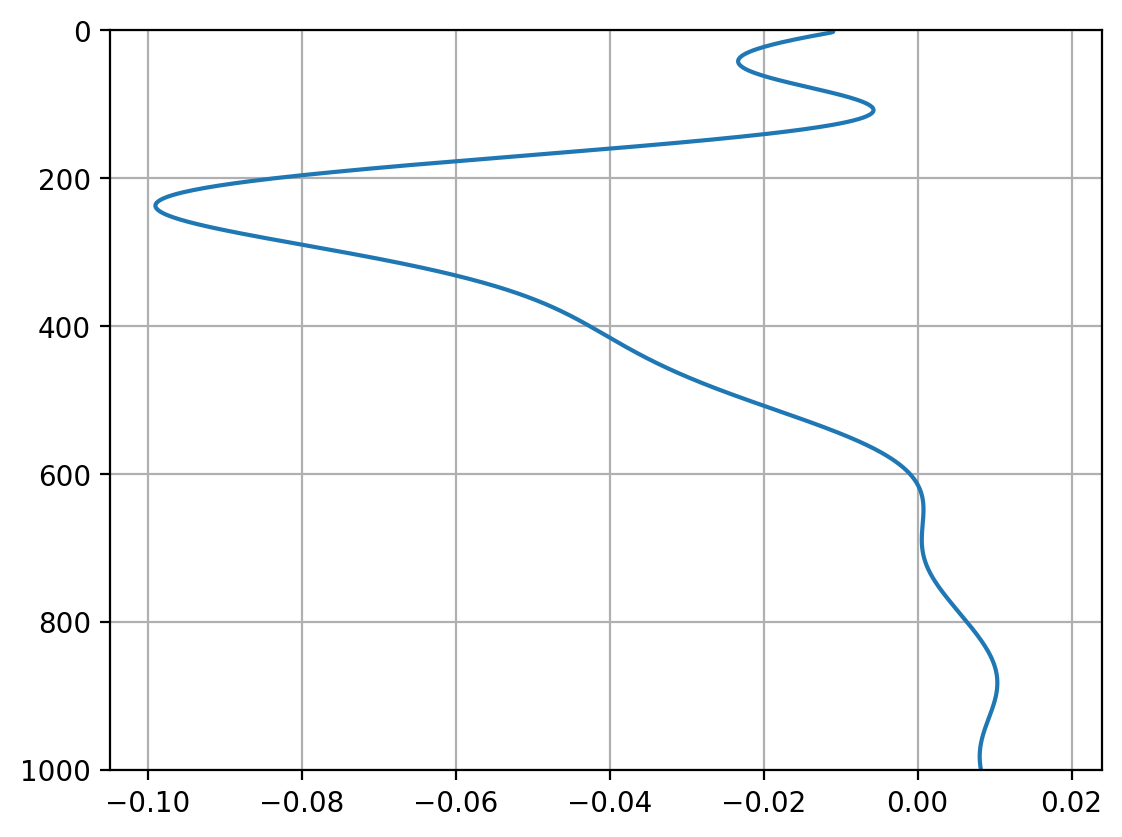

In [83]:
plt.plot(full_field["c"].differentiate("depth").sel({"range": 88000}), full_field.depth)
plt.ylim([1000, 0])
plt.grid()

(1000.0, 0.0)

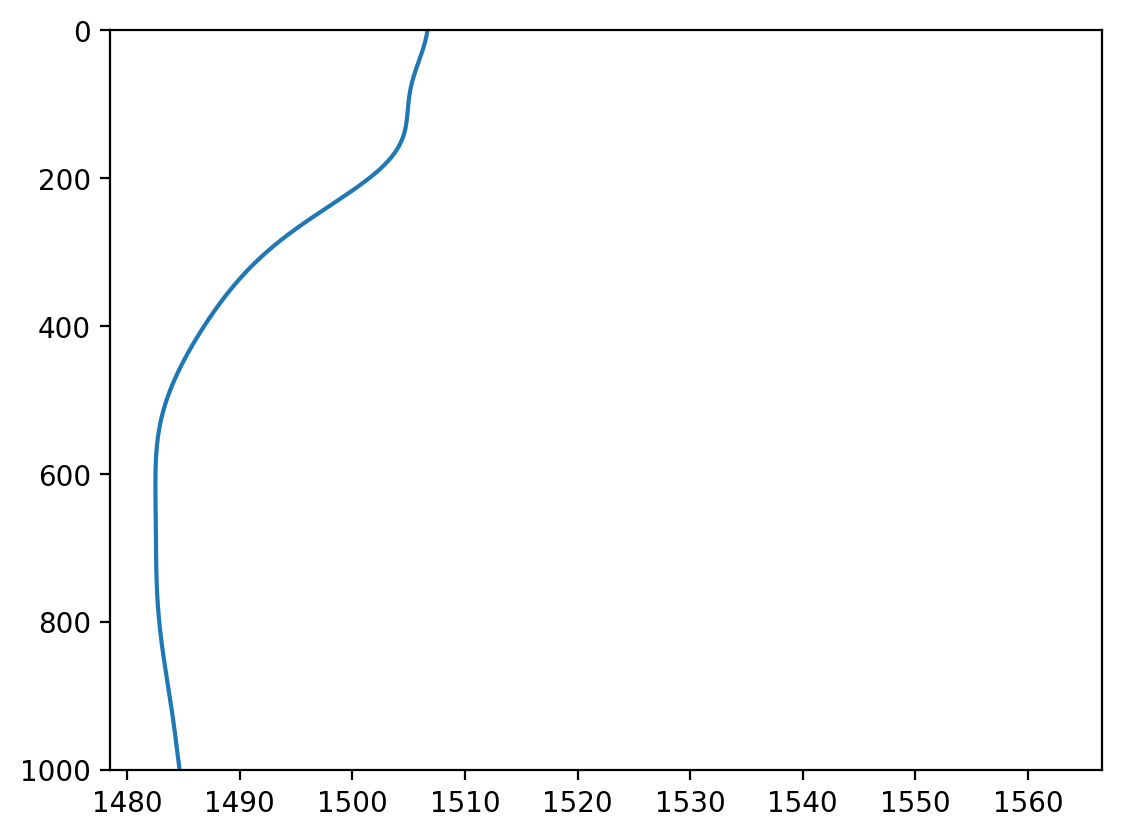

In [82]:
plt.plot(full_field["c"].sel({"range": 88000}), full_field.depth)
plt.ylim([1000, 0])

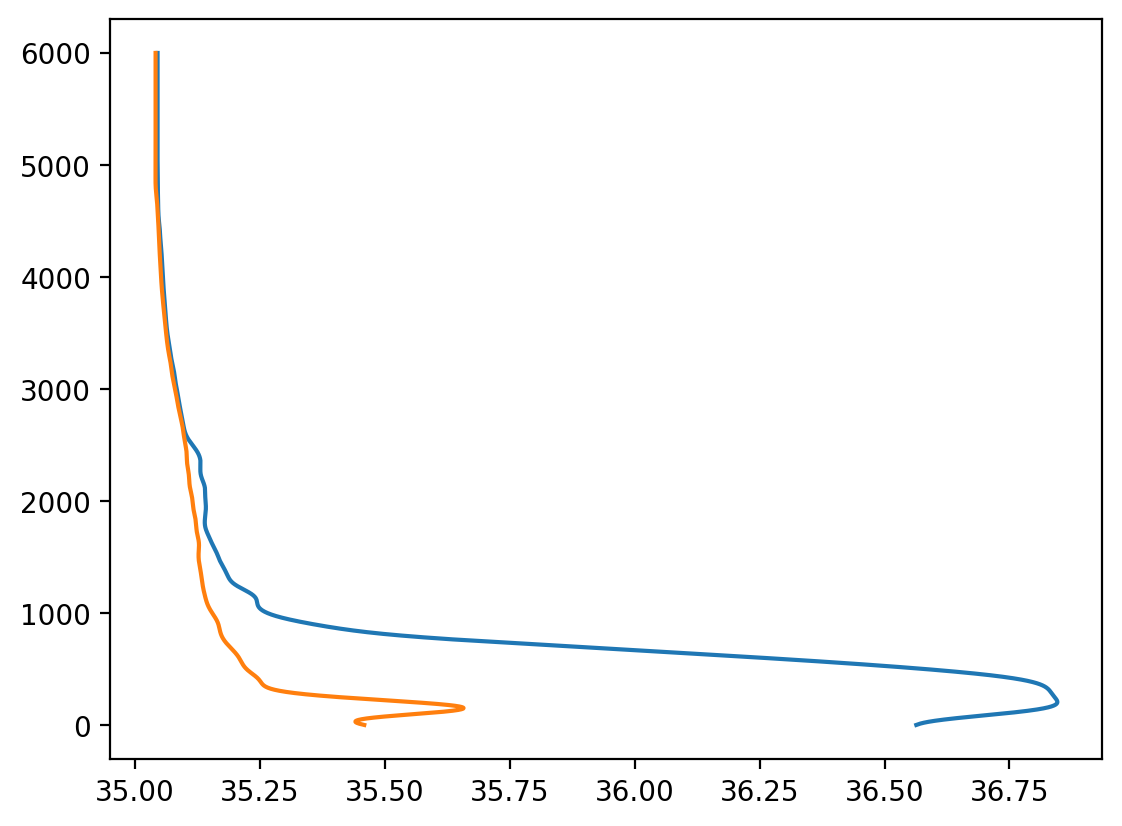

In [20]:
plt.plot(full_field["SA"][:, 0], full_field.depth)
plt.plot(full_field["SA"][:, -1], full_field.depth)

# plt.ylim([300,0])